# 03 · Team-specific tire wear

**Goal:** estimate how hard each team's car is on its tires this season, compared with the field.

Choices carried over from notebooks 01–02:
- **This season only.** The 2026 rules brought new cars, so earlier seasons say little about how today's cars treat tires.
- **Opening laps dropped** (laps 2–6), because start-of-race traffic distorts wear estimates.
- **Mediums and hards only** get team-specific rates. 2026 soft data is too thin to split by team, so softs share one field-wide rate.

In [1]:
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from degradation import (bootstrap, eligible_teams, fit_degradation,
                         fit_team_degradation, partial_pool, summarize)

REF_LAP = 90           # seconds; converts % into seconds on a typical lap
SKIP = 5               # opening laps to drop after lap 1 (notebook 02)
COMPOUNDS = ["MEDIUM", "HARD"]
K = REF_LAP / 100

laps = pd.read_parquet(Path("..") / "app" / "data" / "clean_laps.parquet")
SEASON = int(laps["SEASON"].max())
season = laps[laps["SEASON"] == SEASON]

usable = season[season["LAP_NUMBER"] > 1 + SKIP]
usable.groupby(["TEAM", "COMPOUND"]).size().unstack(fill_value=0)

COMPOUND,HARD,MEDIUM,SOFT
TEAM,,,
Alpine,854,474,141
Aston Martin,262,291,508
Audi,578,458,304
Cadillac,384,443,254
Ferrari,709,429,360
Haas F1 Team,800,398,221
McLaren,713,448,200
Mercedes,836,490,201
Racing Bulls,689,515,268


## 1. The field-wide baseline

The same model as before, on this season with opening laps dropped. Every team will be compared against these numbers.

In [2]:
field = fit_degradation(season, skip_opening_laps=SKIP)
field_boot = bootstrap(season, n=200, skip_opening_laps=SKIP)
summarize(field, field_boot, REF_LAP).round(3)

,estimate,low (2.5%),high (97.5%)
fuel,-0.040,-0.047,-0.034
deg_SOFT,0.017,-0.006,0.039
deg_MEDIUM,0.030,0.018,0.045
deg_HARD,0.029,0.013,0.050
offset_SOFT,0.084,-0.263,0.477
offset_HARD,-0.056,-0.315,0.242


## 2. Raw team estimates

Each team gets its own wear rate on mediums and hards. Fuel, the compound offsets, and soft wear stay shared, since they're about physics and tire design more than the car.

Teams with fewer than 150 usable laps on a compound are grouped as "other teams" for that compound: too little data to say anything about them individually.

Bootstrapping by race (200 resamples) gives each team's uncertainty. This cell takes a minute or so.

In [3]:
eligible = eligible_teams(season, COMPOUNDS, min_laps=150, skip_opening_laps=SKIP)
team_est = fit_team_degradation(season, eligible, skip_opening_laps=SKIP)
team_boot = bootstrap(season, n=200, fit_fn=fit_team_degradation,
                      eligible=eligible, skip_opening_laps=SKIP)
{c: len(t) for c, t in eligible.items()}

{'MEDIUM': 11, 'HARD': 11}

## 3. Partial pooling

Raw team estimates mix real differences with noise. A team with few laps on hards can look extreme by chance.

**Partial pooling** pulls each team toward the field average, by an amount that depends on how uncertain its estimate is:
- **weight near 1:** the team has plenty of data, so it keeps its own estimate.
- **weight near 0:** the team's data is too noisy to trust, so it gets close to the field average.

If teams barely differ beyond noise, everyone is pulled close to the field average. The data decides how much teams really differ.

**Measuring each team's uncertainty correctly.** Circuits differ a lot in how hard they are on tires, so the field-wide wear rate swings depending on which races a resample happens to include. That swing hits every team equally, since everyone races at the same circuits, so it shouldn't count as uncertainty about how teams *compare*. Each team's uncertainty is therefore measured on its **difference from the field within the same resample**. (A first version used each team's overall uncertainty instead, which over-counted circuit variation and pulled every team all the way back to the field average.)

In [4]:
pooled = {}
for c in COMPOUNDS:
    cols = [f"{c}|{t}" for t in eligible[c]]
    # Uncertainty of each team's DIFFERENCE from the field, within each resample.
    # bootstrap() draws the same races for the same seed, so row i of team_boot and
    # row i of field_boot come from the same resample.
    diff_se = team_boot[cols].sub(field_boot[f"deg_{c}"], axis=0).std()
    p = partial_pool(team_est[cols], diff_se, field[f"deg_{c}"])
    p.index = [i.split("|")[1] for i in p.index]
    pooled[c] = p

table = pd.concat(pooled, names=["compound", "team"])
seconds = table[["raw", "pooled", "low", "high"]] * K
seconds["weight"] = table["weight"]
seconds.round(3)

raw  pooled    low   high  weight
compound team                                                
MEDIUM   Alpine           0.014   0.027  0.019  0.034   0.217
         Aston Martin     0.024   0.029  0.022  0.037   0.109
         Audi             0.028   0.030  0.023  0.037   0.289
         Cadillac         0.039   0.032  0.025  0.040   0.219
         Ferrari          0.030   0.030  0.024  0.036   0.431
         Haas F1 Team     0.041   0.032  0.024  0.039   0.162
         McLaren          0.036   0.031  0.024  0.039   0.192
         Mercedes         0.021   0.026  0.020  0.032   0.452
         Racing Bulls     0.040   0.034  0.027  0.040   0.368
         Red Bull Racing  0.036   0.032  0.025  0.039   0.320
         Williams         0.024   0.029  0.021  0.036   0.187
HARD     Alpine           0.021   0.027  0.022  0.032   0.223
         Aston Martin     0.038   0.029  0.023  0.035   0.048
         Audi             0.031   0.029  0.024  0.034   0.254
         Cadillac         0.036   0.029  0.024  0.035   0.124
         Ferrari          0.033   0.030  0.025  0.035   0.250
         Haas F1 Team     0.045   0.031  0.026  0.037   0.153
         McLaren          0.029   0.029  0.023  0.034   0.148
         Mercedes         0.017   0.027  0.021  0.032   0.152
         Racing Bulls     0.024   0.028  0.022  0.033   0.205
         Red Bull Racing  0.029   0.029  0.024  0.034   0.273
         Williams         0.031   0.029  0.024  0.034   0.166

## 4. Team wear rates, with 95% ranges

Teams are sorted from gentlest to hardest on their tires. The dotted line is the field average. Hollow circles show the raw estimates before pooling, so you can see how far each team was pulled in.

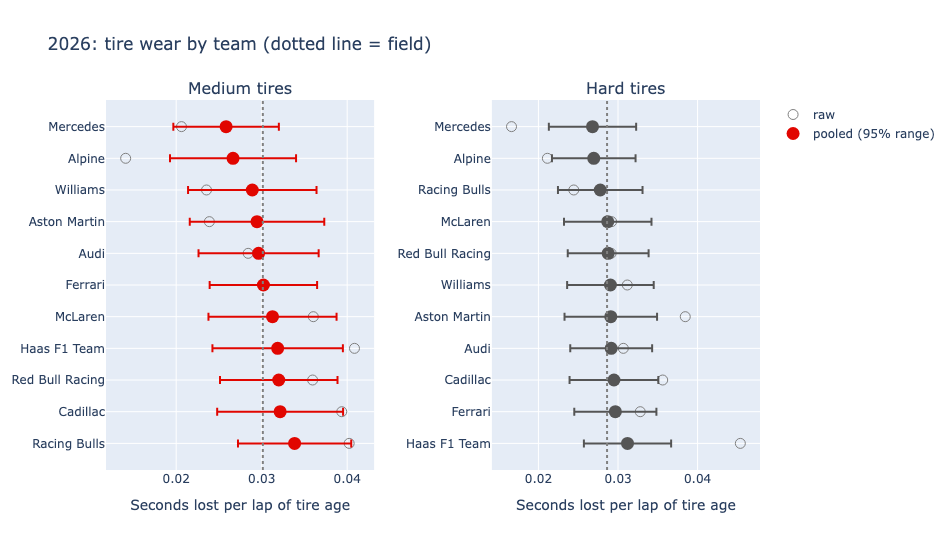

In [5]:
fig = make_subplots(rows=1, cols=2, subplot_titles=[f"{c.title()} tires" for c in COMPOUNDS],
                    horizontal_spacing=0.18)
for i, c in enumerate(COMPOUNDS, 1):
    p = pooled[c].sort_values("pooled", ascending=False).copy()   # gentlest ends up on top
    p[["raw", "raw_se", "pooled", "low", "high"]] *= K            # % -> seconds
    fig.add_trace(go.Scatter(x=p["raw"], y=p.index, mode="markers", name="raw",
                             marker=dict(symbol="circle-open", size=10, color="gray"),
                             showlegend=(i == 1)), row=1, col=i)
    fig.add_trace(go.Scatter(
        x=p["pooled"], y=p.index, mode="markers", name="pooled (95% range)",
        marker=dict(size=13, color="#E10600" if c == "MEDIUM" else "#555"),
        error_x=dict(type="data", symmetric=False,
                     array=p["high"] - p["pooled"], arrayminus=p["pooled"] - p["low"]),
        showlegend=(i == 1)), row=1, col=i)
    fig.add_vline(x=field[f"deg_{c}"] * K, line_dash="dot", line_color="gray", row=1, col=i)
    fig.update_xaxes(title_text="Seconds lost per lap of tire age", row=1, col=i)
fig.update_layout(height=550, title=f"{SEASON}: tire wear by team (dotted line = field)")
fig.show()

**How to read this:** a team whose range sits entirely left of the dotted line is clearly easier on that tire than the field. If a team's range crosses the line, the data can't distinguish it from average. The ranges describe each team's difference from the field, so they're for comparing teams, not for the field's overall wear level (see section 1 for that).

## 5. Ranking: who is easiest on their tires?

Each team's wear relative to the field, averaged over mediums and hards. −20% means the team loses 20% less time per lap of tire age than an average car.

In [6]:
rel = pd.DataFrame({c: (pooled[c]["pooled"] / field[f"deg_{c}"] - 1) * 100 for c in COMPOUNDS})
rel["average"] = rel.mean(axis=1)
rel.sort_values("average").round(1).rename(columns=lambda c: f"{c} vs field (%)")

,MEDIUM vs field (%),HARD vs field (%),average vs field (%)
Mercedes,-14.3,-6.4,-10.3
Alpine,-11.6,-5.8,-8.7
Williams,-4.1,1.5,-1.3
Aston Martin,-2.3,1.6,-0.3
Audi,-1.6,1.8,0.1
Ferrari,0.2,3.6,1.9
McLaren,3.8,0.3,2.0
Red Bull Racing,6.2,0.5,3.3
Racing Bulls,12.3,-3.0,4.7
Cadillac,6.7,3.0,4.9


## 6. Save for the dashboard

Saves the pooled team rates so the Streamlit app can show them. (For now, rerun this notebook to refresh them; we'll automate it with the weekly pipeline later.)

In [7]:
out = table.reset_index()
out[["raw", "pooled", "low", "high", "raw_se"]] *= K   # store in seconds
out["season"] = SEASON
out["field_wear"] = out["compound"].map({c: field[f"deg_{c}"] * K for c in COMPOUNDS})
out.to_parquet(Path("..") / "app" / "data" / "team_wear.parquet", index=False)
out.head()

,compound,team,raw,raw_se,weight,pooled,low,high,season,field_wear
0,MEDIUM,Alpine,0.014091,0.008068,0.217268,0.026649,0.019278,0.034020,2026,0.030134
1,MEDIUM,Aston Martin,0.023879,0.012167,0.108782,0.029454,0.021588,0.037319,2026,0.030134
2,MEDIUM,Audi,0.028418,0.006664,0.289225,0.029638,0.022614,0.036662,2026,0.030134
3,MEDIUM,Cadillac,0.039366,0.008024,0.219169,0.032158,0.024795,0.039520,2026,0.030134
4,MEDIUM,Ferrari,0.030284,0.004882,0.431199,0.030199,0.023915,0.036483,2026,0.030134


## Caveats

- **"Team" means the car, the drivers, and their choices together.** A team that deliberately manages tire wear to make a one-stop work will look gentle on tires, even if the car isn't special.
- **Wear is assumed to be linear:** the same loss every lap. Real tires can fall off a cliff late in a stint; this model averages over that.
- **Each team has only one season of data on the new cars,** so ranges are wide. They'll narrow as the season goes on.

## Next

Use these rates in a **strategy simulator**: for each team at an upcoming circuit, compare one-stop and two-stop plans using its wear rates, the fuel effect, and that circuit's pit-lane time loss.